# Multiple Linear Regression from Scratch: Medical Cost Prediction

This notebook implements an end-to-end **Multiple Linear Regression** model from first principles using **NumPy** to predict individual annual medical insurance charges from demographic and health attributes.

### Project Workflow Overview:
1. **Environment Setup & Data Ingestion**: Load the raw microdata (`insurance.csv`, $N = 1,338$) and audit data hygiene.
2. **Exploratory Data Analysis (EDA)**: Inspect target distributions and examine bivariate associations across covariates.
3. **Data Preprocessing Pipeline**: Remove exact duplicate rows, partition into train/val/test splits ($70\% / 15\% / 15\%$), apply binary and one-hot encoding, and standardize continuous features.
4. **First-Principles Optimization**: Implement vectorized hypothesis, cost function, analytic gradients, and batch gradient descent.
5. **Learning Rate Experiments**: Systematically evaluate candidate step sizes ($\alpha$) for convergence speed and numerical stability.
6. **Model Evaluation & Residual Diagnostics**: Benchmark generalization performance on training, validation, and holdout test partitions using MAE, RMSE, and $R^2$.

## 1. Environment Configuration and Project Paths

Establish project root paths and import data preprocessing, linear regression, and visualization modules from `src/`.

In [24]:
from pathlib import Path
import sys

# Locate the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw" / "insurance.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data" / "raw" / "insurance.csv").exists():
    raise FileNotFoundError("Could not locate data/raw/insurance.csv")

sys.path.insert(0, str(PROJECT_ROOT))

from src.data_preprocessing import (
    load_data,
    clean_data,
    split_data,
    encode_categorical_features,
    scale_continuous_features,
    convert_to_numpy
)

from src.visualization import (
    plot_raw_data,
    plot_preprocessed_data
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "insurance.csv"
FIGURES_PATH = PROJECT_ROOT / "outputs" / "figures"

## 2. Data Loading and Initial Quality Audit

Load the raw dataset and inspect dimensional shape, attribute types, summary statistics, missing values, and duplicate records.

In [8]:
df_raw = load_data(DATA_PATH)

print("Dataset shape", df_raw.shape)
print("\n Column names:")
print(df_raw.columns.tolist())

print("\nFirst five rows:")
display(df_raw.head())

print("\nData types and non null counts:")
df_raw.info()

print("\nMissing values:")
display(df_raw.isnull().sum())

print("\nDuplicate rows:", df_raw.duplicated().sum())

Dataset shape (1338, 7)

 Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

First five rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Data types and non null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Missing values:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Duplicate rows: 1


## 3. Exploratory Data Analysis (EDA)

Visualize the empirical distribution of the target variable (`charges`) and examine relationships with continuous features (`age`, `bmi`) and categorical cohorts (`smoker`, `region`).

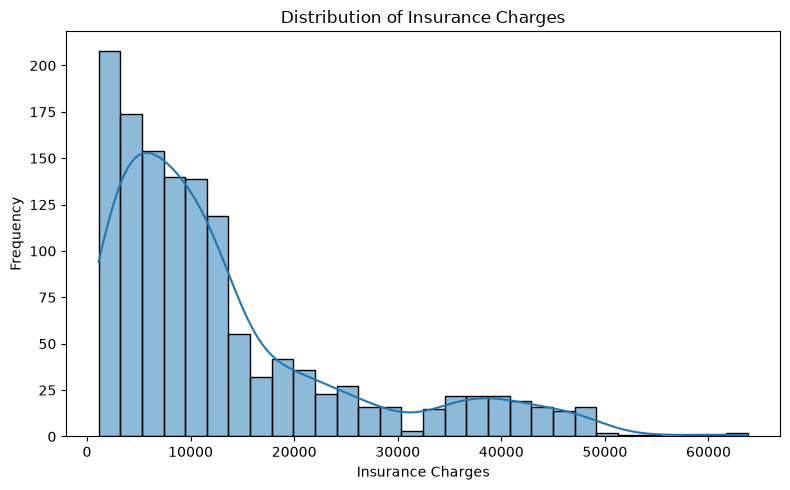

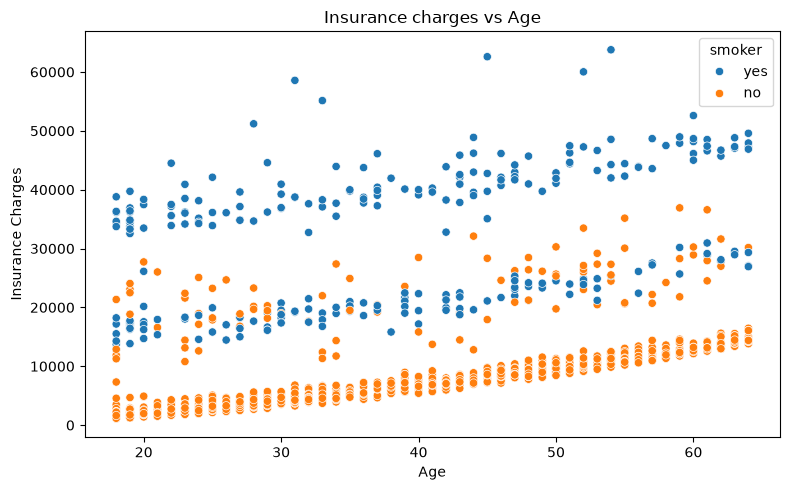

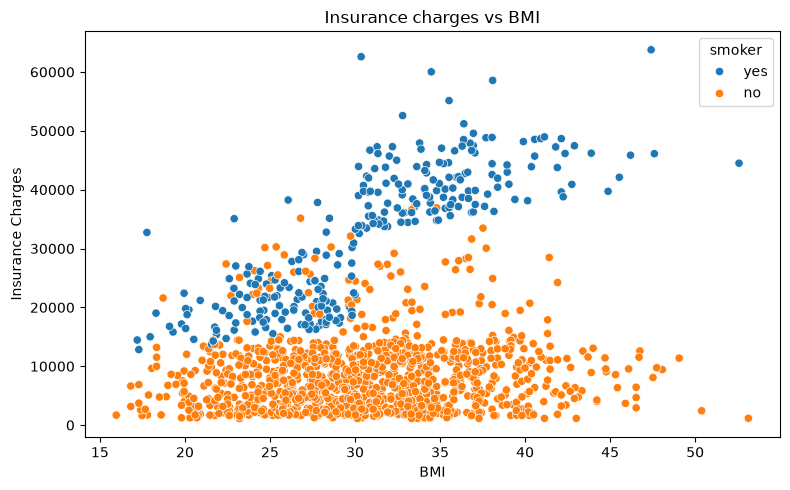

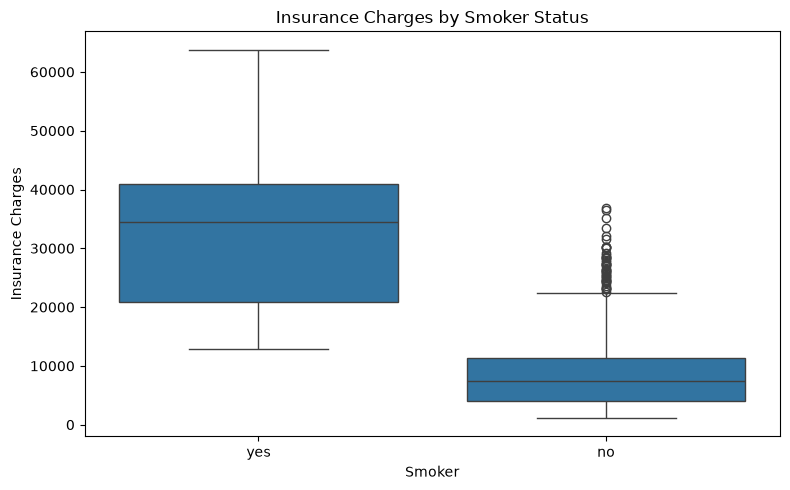

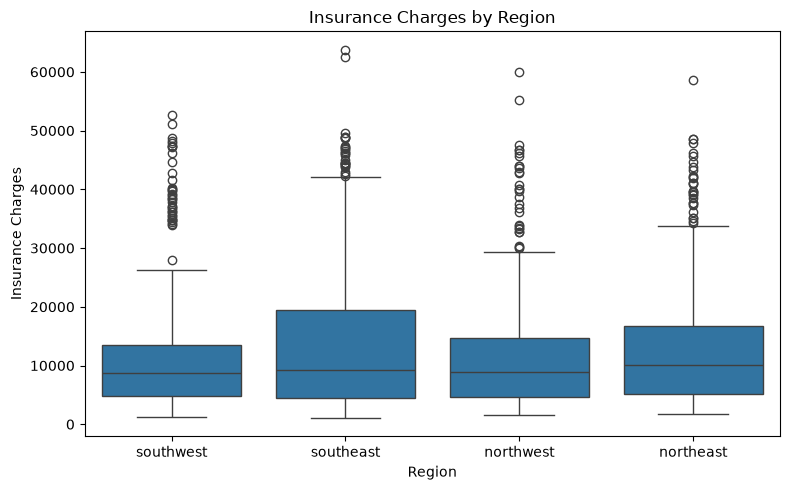

In [11]:
plot_raw_data(df_raw, FIGURES_PATH)

## 4. Data Preprocessing Pipeline

### 4.1 Data Cleaning & Train-Validation-Test Partitioning
- **Deduplication**: Remove exact duplicate rows to prevent artificial weighting during parameter optimization ($1,338 \to 1,337$ records).
- **Three-Way Partition**: Split into **70% Training** ($N = 935$), **15% Validation** ($N = 201$), and **15% Test** ($N = 201$) using fixed `random_state=42`.

In [12]:
df = clean_data(df_raw)

print("Cleaned dataset shape:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

(
    X_train_raw, X_val_raw, X_test_raw,
    y_train, y_val, y_test
) = split_data(df)

print("\nTraining features:", X_train_raw.shape)
print("Validation features:", X_val_raw.shape)
print("Test features:", X_test_raw.shape)

Cleaned dataset shape: (1337, 7)
Remaining duplicate rows: 0

Training features: (935, 6)
Validation features: (201, 6)
Test features: (201, 6)


### 4.2 Categorical Feature Encoding
- **Binary Mapping**: Map dichotomous features to numerical indicators:
  - `sex`: `female` $\to 0$, `male` $\to 1$
  - `smoker`: `no` $\to 0$, `yes` $\to 1$
- **One-Hot Encoding**: Encode `region` with `northeast` omitted as the baseline reference category to prevent the **dummy variable trap** (perfect multicollinearity).

In [13]:
(
    X_train_encoded,
    X_val_encoded,
    X_test_encoded
) = encode_categorical_features(
    X_train_raw,
    X_val_raw,
    X_test_raw
)

print("\nEncoded training shape:", X_train_encoded.shape)
print("Encoded columns:")
print(X_train_encoded.columns.tolist())

display(X_train_encoded.head())


Encoded training shape: (935, 8)
Encoded columns:
['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']


,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
138,54,0,31.900,3,0,0,1,0
381,55,1,30.685,0,1,0,0,0
292,25,1,45.540,2,1,0,1,0
1089,47,1,36.190,0,1,0,1,0
892,47,1,38.940,2,1,0,1,0


### 4.3 Feature Standardization ($Z$-Score Normalization)
Standardize continuous predictors (`age`, `bmi`, `children`) to zero mean and unit variance:

$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

> **Anti-Leakage Protocol**: Mean ($\mu_{\text{train}}$) and standard deviation ($\sigma_{\text{train}}$) are computed **strictly from the training split** and applied out-of-sample to validation and test sets. The target variable `charges` remains unscaled in native dollars (\$).

In [14]:
(
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    scaler
) = scale_continuous_features(
    X_train_encoded,
    X_val_encoded,
    X_test_encoded
)

display(X_train_scaled.head())

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
138,1.071358,0,0.212671,1.599870,0,0,1,0
381,1.142828,1,0.010871,-0.905789,1,0,0,0
292,-1.001264,1,2.478147,0.764650,1,0,1,0
1089,0.571070,1,0.925200,-0.905789,1,0,1,0
892,0.571070,1,1.381949,0.764650,1,0,1,0


### 4.4 Visualizing Preprocessed Features
Verify that standardized continuous features are centered near zero with unit standard deviation.

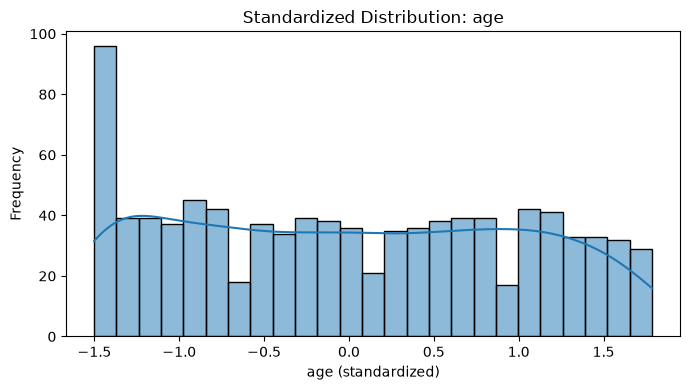

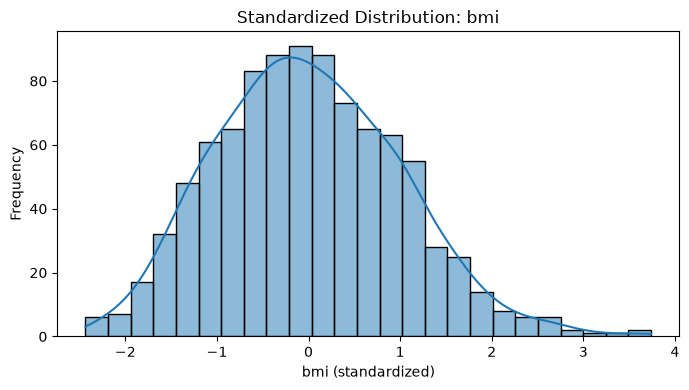

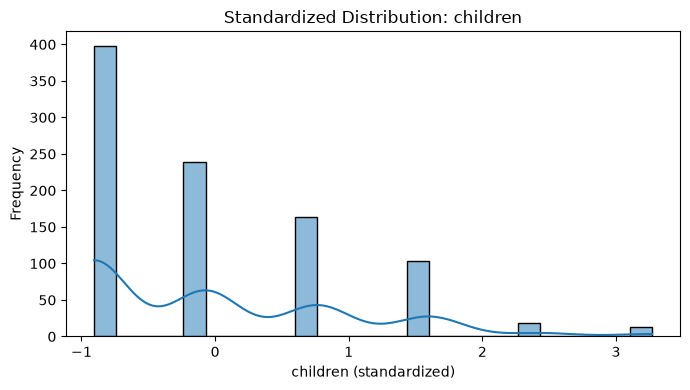

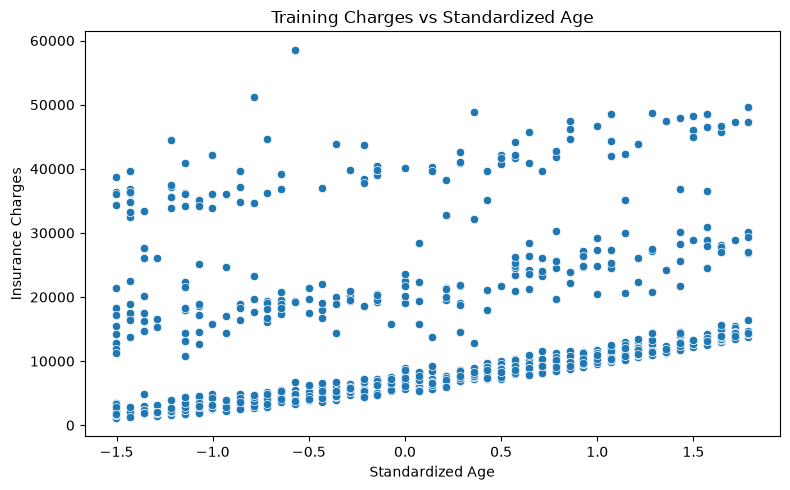

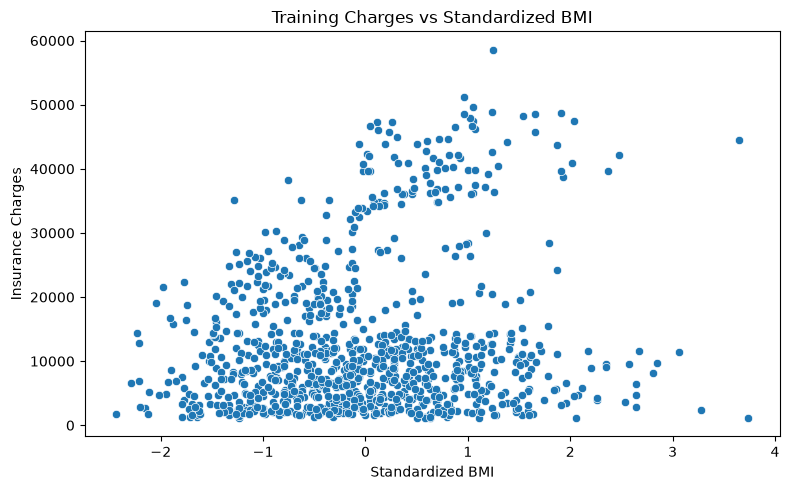

In [116]:
plot_preprocessed_data(
    X_train_scaled,
    y_train,
    FIGURES_PATH
)

### 4.5 Tensor Serialization and Dimensional Verification
Convert processed pandas DataFrames into contiguous `float64` NumPy arrays with explicit 2D column-vector targets ($\mathbf{Y} \in \mathbb{R}^{m \times 1}$) to avoid broadcasting inconsistencies.

In [30]:
(
    X_train, X_val, X_test,
    Y_train, Y_val, Y_test
) = convert_to_numpy(
    X_train_scaled, X_val_scaled, X_test_scaled,
    y_train, y_val, y_test
)

In [31]:
print("Training:")
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)

print("\nValidation")
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

print("\nTest:")
print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

print("\nData types:")
print("X_train:", X_train.dtype)
print("Y_train:", Y_train.dtype)

Training:
X_train: (935, 8)
Y_train: (935, 1)

Validation
X_val: (201, 8)
Y_val: (201, 1)

Test:
X_test: (201, 8)
Y_test: (201, 1)

Data types:
X_train: float64
Y_train: float64


In [ ]:
assert X_train.ndim == 2
assert Y_train.ndim == 2

assert X_train.shape[0] == Y_train.shape[0]
assert X_train.shape[1] == 8
assert Y_train.shape[1] == 1

assert np.isfinite(X_train).all()
assert np.isfinite(Y_train).all()

assert X_train.shape[0] == 935
assert Y_train.shape == (935, 1)

print("All training matrix checks passed.")

All training matrix checks passed.


## 5. Multiple Linear Regression from First Principles

### 5.1 Mathematical Formulations
- **Linear Hypothesis**:
  $$\hat{\mathbf{Y}} = \mathbf{X}\mathbf{W} + b\mathbf{1}_m$$
- **Half-MSE Objective Function**:
  $$J(\mathbf{W}, b) = \frac{1}{2m} \|\hat{\mathbf{Y}} - \mathbf{Y}\|_2^2 = \frac{1}{2m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2$$
- **Analytical Gradient Vectors**:
  $$\nabla_{\mathbf{W}} J = \frac{1}{m} \mathbf{X}^T (\hat{\mathbf{Y}} - \mathbf{Y}), \quad \nabla_b J = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$
- **Batch Gradient Descent Parameter Updates**:
  $$\mathbf{W}^{(t+1)} = \mathbf{W}^{(t)} - \alpha \nabla_{\mathbf{W}} J^{(t)}, \quad b^{(t+1)} = b^{(t)} - \alpha \nabla_b J^{(t)}$$

In [ ]:
import numpy as np
import importlib
import src.linear_regression, src.visualization
importlib.reload(src.linear_regression)
importlib.reload(src.visualization)
from src.linear_regression import gradient_descent, compute_cost, predict
from src.visualization import plot_learning_curve, plot_selected_candidates_comparison

### 5.2 Initial Learning Rate Trajectory Sweep
Execute batch gradient descent across candidate step sizes $\alpha \in \{0.2, 0.3, 1.0, 1.3\}$ for $T = 1,000$ iterations to observe convergence vs. divergence behaviors.

In [87]:
learning_rates = [0.2, 0.3, 1, 1.3]

results = {}

for alpha in learning_rates:
    W_trained, b_trained, J_history, iterations = gradient_descent(
    X_train,
    Y_train,
    alpha,
    num_iters=1000
    )

    results[alpha] = {
        "W": W_trained,
        "b": b_trained,
        "J_history": J_history,
        "iterations": iterations
    }

    print(f"\n\nLearning rate: {alpha}")
    print(f"Initial recorded cost: {J_history[0]:,.2f}")
    print(f"Final recorded cost: {J_history[-1]:,.2f}")
    print(f"All costs finite?: {np.isfinite(J_history).all()}")
    print(f"Cost decreased?: {J_history[-1] < J_history[0]}")



Learning rate: 0.2
Initial recorded cost: 38,212,551.50
Final recorded cost: 17,906,466.62
All costs finite?: True
Cost decreased?: True


Learning rate: 0.3
Initial recorded cost: 32,436,043.27
Final recorded cost: 17,906,466.62
All costs finite?: True
Cost decreased?: True


Learning rate: 1
Initial recorded cost: 19,263,137.64
Final recorded cost: 17,906,466.62
All costs finite?: True
Cost decreased?: True


Learning rate: 1.3
Initial recorded cost: 275,899,136.47
Final recorded cost: 554,283,055,024,984,482,464,086,228,772,643,942,202,773,198,157,643,776.00
All costs finite?: True
Cost decreased?: False


### 5.3 Visualizing Individual Optimization Trajectories
Plot and save objective cost trajectories $J(\mathbf{W}, b)$ over iterations for each evaluated learning rate.

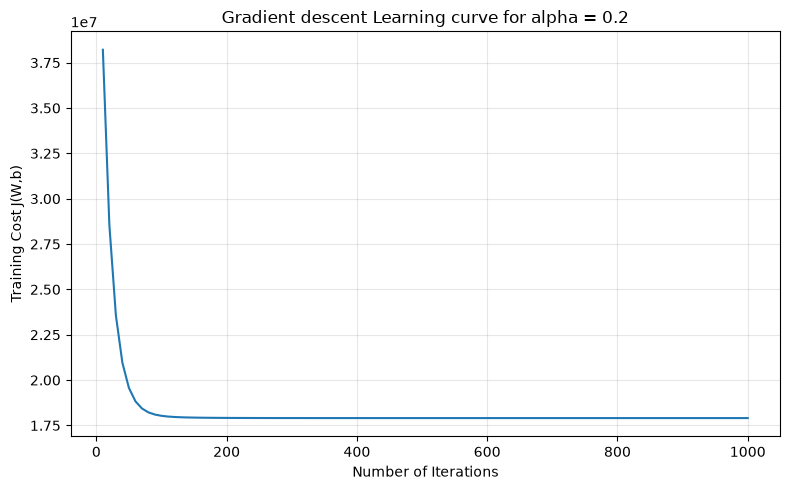

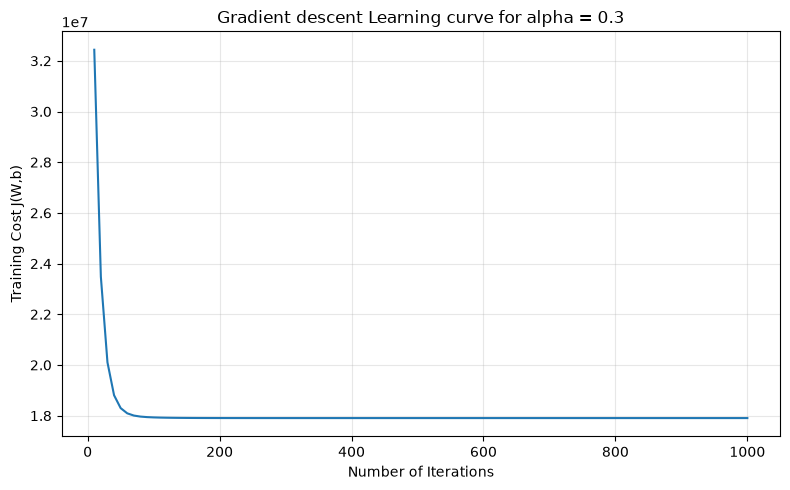

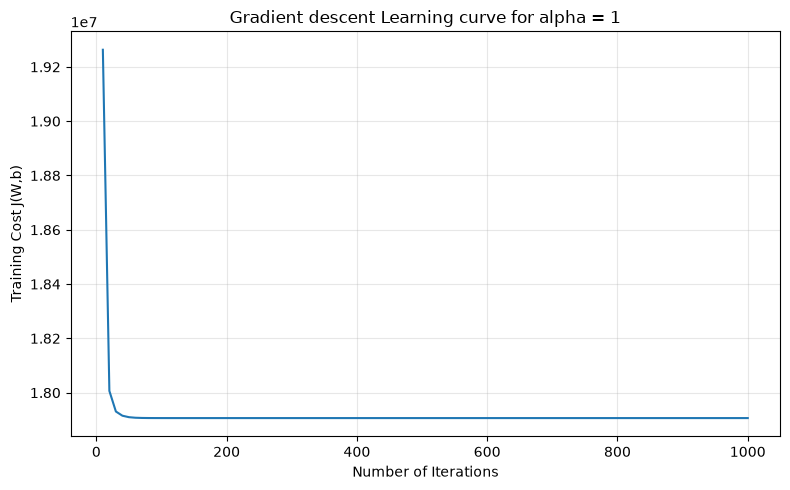

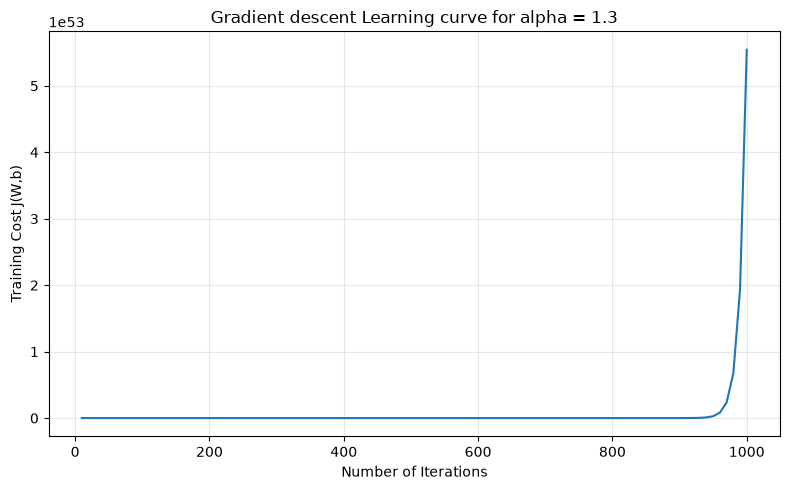

In [88]:
for alpha, result in results.items():
    plot_learning_curve(
        result["J_history"],
        result["iterations"],
        alpha,
        FIGURES_PATH
    )

### 5.4 Multi-Candidate Comparison on Training and Validation Partitions
Evaluate shortlisted candidate rates $\alpha \in \{0.1, 0.2, 0.3, 1.0\}$ on both training cost and unseen validation cost, while verifying checkpoint monotonicity.

In [90]:
candidate_alphas = [0.1, 0.2, 0.3, 1]
final_results = {}

for alpha in candidate_alphas:
    W, b, J_history, iterations = gradient_descent(
        X_train,
        Y_train,
        alpha,
        num_iters=1000
    )

    train_cost = compute_cost(X_train, Y_train, W, b)
    val_cost = compute_cost(X_val, Y_val, W, b)

    final_results[alpha] = {
        "W": W,
        "b": b,
        "J_history": J_history,
        "iterations": iterations,
        "train_cost": train_cost,
        "val_cost": val_cost
    }

    print(f"\nAlpha: {alpha}")
    print(f"Training cost:   {train_cost:,.2f}")
    print(f"Validation cost: {val_cost:,.2f}")
    print(f"All recorded costs finite: {np.isfinite(J_history).all()}")
    print(f"Checkpoint costs non-increasing:{np.all(np.diff(J_history) <= 0)}")


Alpha: 0.1
Training cost:   17,906,499.16
Validation cost: 19,954,613.43
All recorded costs finite: True
Checkpoint costs non-increasing:True

Alpha: 0.2
Training cost:   17,906,466.62
Validation cost: 19,950,272.19
All recorded costs finite: True
Checkpoint costs non-increasing:True

Alpha: 0.3
Training cost:   17,906,466.62
Validation cost: 19,950,234.93
All recorded costs finite: True
Checkpoint costs non-increasing:True

Alpha: 1
Training cost:   17,906,466.62
Validation cost: 19,950,234.61
All recorded costs finite: True
Checkpoint costs non-increasing:False


### 5.5 Candidate Convergence Comparison
Compare the learning curves of shortlisted candidates to evaluate optimization speed and final plateau attainment.

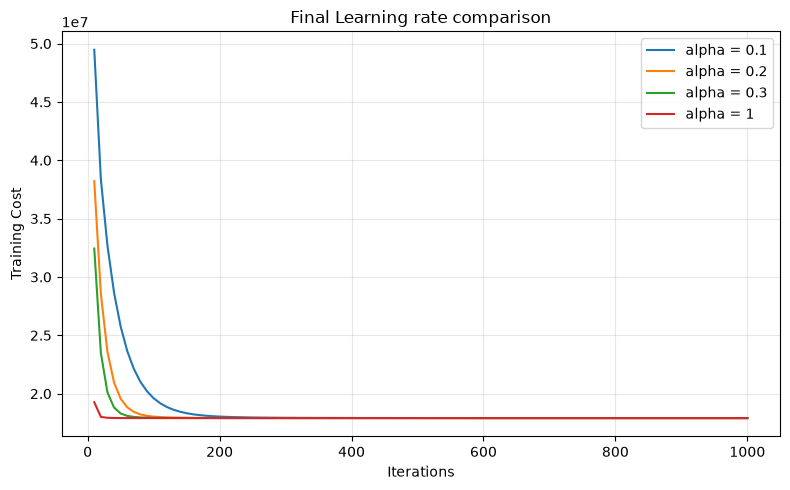

In [94]:
plot_selected_candidates_comparison(final_results, FIGURES_PATH)

### 5.6 Optimal Model Selection ($\alpha = 0.3$)
Select **$\alpha = 0.3$** as the final learning rate based on minimal monotonic validation cost and numerical stability. Extract optimal parameters $\mathbf{W}_{\text{best}}$ and $b_{\text{best}}$.

In [95]:
best_alpha = 0.3

best_result = final_results[best_alpha]

W_best = best_result["W"]
b_best = best_result["b"]
J_history_best = best_result["J_history"]
iterations_best = best_result["iterations"]

print("Selected learning rate:", best_alpha)
print("Weights shape:", W_best.shape)
print("Bias:", b_best)
print("Final training cost:", best_result["train_cost"])
print("Final validation cost:", best_result["val_cost"])

Selected learning rate: 0.3
Weights shape: (8, 1)
Bias: 8905.451304109707
Final training cost: 17906466.618087325
Final validation cost: 19950234.927203286


### 5.7 Final Production Model Learning Curve
Plot the complete training trajectory for the selected model ($\alpha = 0.3$), illustrating rapid descent and asymptotic flattening.

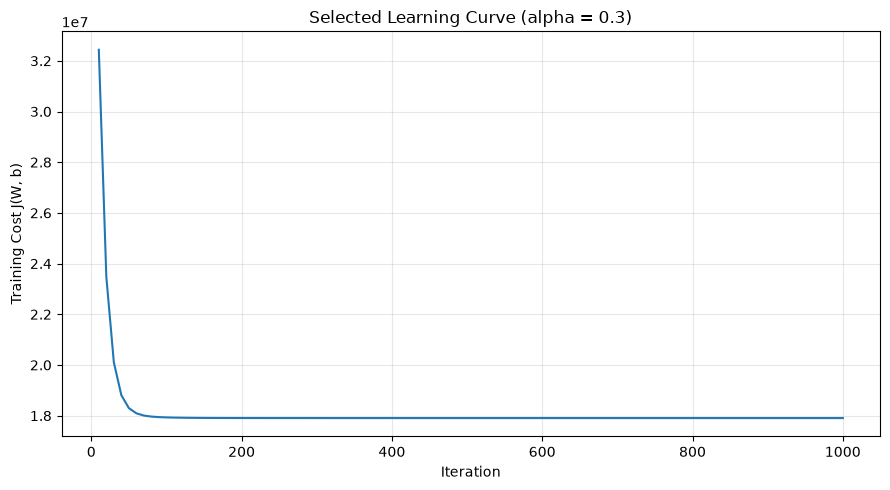

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(iterations_best, J_history_best)

plt.xlabel("Iteration")
plt.ylabel("Training Cost J(W, b)")
plt.title(f"Selected Learning Curve (alpha = {best_alpha})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_PATH / "final_gradient_descent_learning_curve.png",
    dpi=150
)
plt.show()

## 6. Model Evaluation and Residual Diagnostics

### 6.1 Prediction Generation and Metric Definitions
Generate predictions on training and validation sets:
$$\hat{\mathbf{Y}} = \mathbf{X}\mathbf{W}_{\text{best}} + b_{\text{best}}$$

Evaluate performance across three complementary metrics:
- **Mean Absolute Error (MAE)**: $\text{MAE} = \frac{1}{m} \sum_{i=1}^{m} |y^{(i)} - \hat{y}^{(i)}|$ (average expected error in native \$ units)
- **Root Mean Squared Error (RMSE)**: $\text{RMSE} = \sqrt{\frac{1}{m} \sum_{i=1}^{m} (y^{(i)} - \hat{y}^{(i)})^2}$ (penalizes large outlier misses)
- **Coefficient of Determination ($R^2$)**: $R^2 = 1 - \frac{\sum (y^{(i)} - \hat{y}^{(i)})^2}{\sum (y^{(i)} - \bar{y})^2}$ (proportion of explained variance)

In [98]:
# Generate Prediction using the selected model best alpha

Y_train_pred = predict(X_train, W_best, b_best)
Y_val_pred = predict(X_val, W_best, b_best)

print("Training predictions shape:", Y_train_pred.shape)
print("Validation predictions shape:", Y_val_pred.shape)

print("\nFirst 5 actual Training charges:")
print(Y_train[:5].flatten())

print("\n First 5 predicted Training charges:")
print(Y_train_pred[:5].flatten())

print("\nFirst 5 actual Validation charges:")
print(Y_val[:5].flatten())

print("\nFirst 5 predicted Validation charges:")
print(Y_val_pred[:5].flatten())

Training predictions shape: (935, 1)
Validation predictions shape: (201, 1)

First 5 actual Training charges:
[27322.73386 42303.69215 42112.2356  41676.0811  44202.6536 ]

 First 5 predicted Training charges:
[13156.30000677 35140.73206642 32589.69029488 34002.41361722
 35949.77781564]

First 5 actual Validation charges:
[11830.6072   3392.9768   9877.6077  18218.16139  2721.3208 ]

First 5 predicted Validation charges:
[ 9950.42464863  4426.89789032 13272.72410109  4934.21662787
  3262.66985587]


In [108]:
import importlib
import src.metrics_calculation
importlib.reload(src.metrics_calculation)
from src.metrics_calculation import mean_absolute_error, root_mean_squared_error, r_squared

### 6.2 Training and Validation Metric Computation
Compute MAE, RMSE, and $R^2$ to evaluate model calibration and inspect the generalization gap between training and validation data.

In [109]:
# Evaluation Metrics for Training data
mae_training = mean_absolute_error(Y_train, Y_train_pred)
rmse_training = root_mean_squared_error(Y_train, Y_train_pred)
coeff_training = r_squared(Y_train, Y_train_pred)

# Evaluation Metrics for Validation data
mae_validation = mean_absolute_error(Y_val, Y_val_pred)
rmse_validation = root_mean_squared_error(Y_val, Y_val_pred)
coeff_validation = r_squared(Y_val, Y_val_pred)

print("\nMean Absolute Error of Training data:", mae_training)
print("Root Mean Squared Error of Training data:", rmse_training)
print("Coefficient of Determination of Training data:", coeff_training)

print("\nMean Absolute Error of Validation data:", mae_validation)
print("Root Mean Squared Error of Validation data:", rmse_validation)
print("Coefficient of Determination of Validation data:", coeff_validation)


Mean Absolute Error of Training data: 4165.830827718357
Root Mean Squared Error of Training data: 5984.390799085121
Coefficient of Determination of Training data: 0.7362637207024102

Mean Absolute Error of Validation data: 4321.71729490722
Root Mean Squared Error of Validation data: 6316.681870603155
Coefficient of Determination of Validation data: 0.7667796028176191


### 6.3 Diagnostic Visualizations: Actual vs. Predicted & Residual Analysis
Examine actual versus predicted response plots and residual scatter plots ($e = y - \hat{y}$) to evaluate linearity and test for heteroscedasticity.

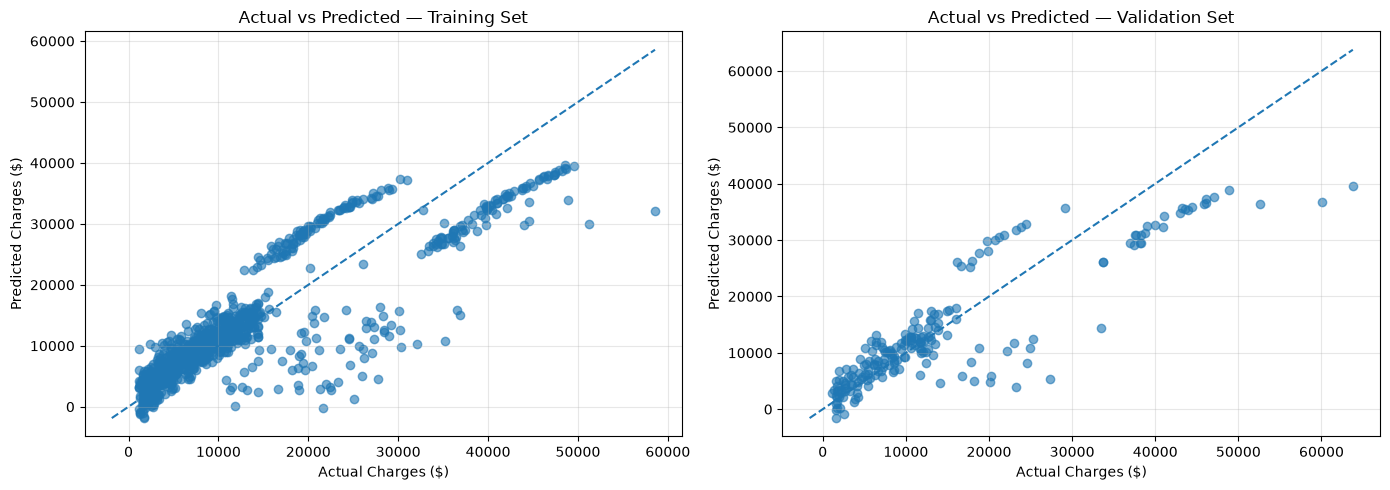

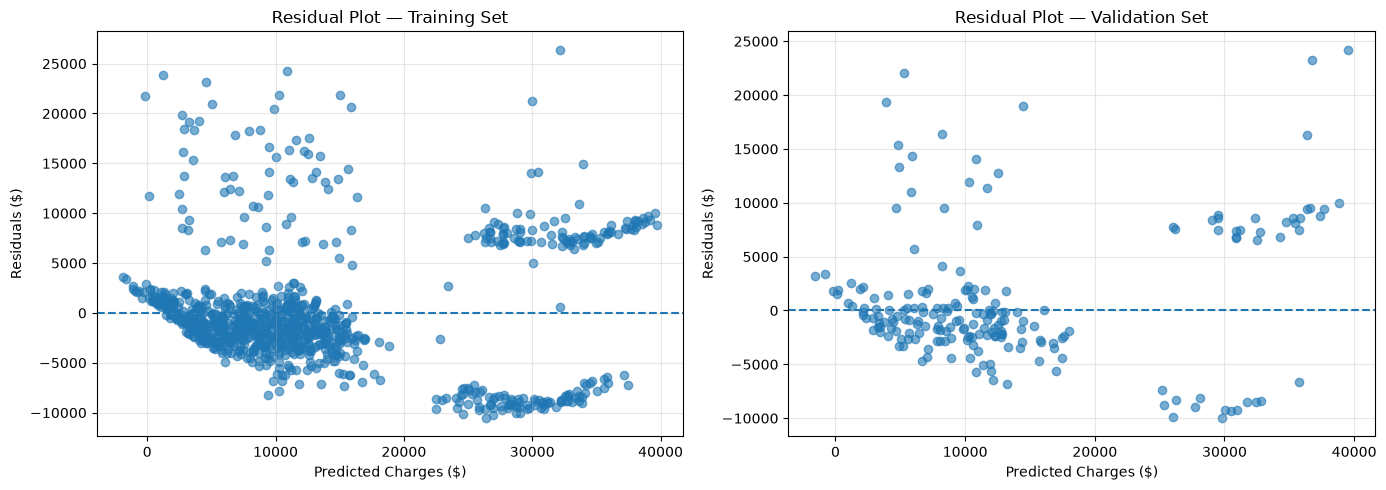

In [113]:
import importlib
importlib.reload(src.visualization)
from src.visualization import plot_predicted_and_actual_curve
plot_predicted_and_actual_curve(Y_train, Y_train_pred, Y_val, Y_val_pred, FIGURES_PATH)

## 7. Final Generalization Benchmark on Untouched Test Set

Evaluate the selected model ($\alpha = 0.3, T = 1,000$) on the **untouched holdout test set** ($N_{\text{test}} = 201$) to establish unbiased out-of-sample performance.

In [114]:
# Final evaluation on the untouched test set
Y_test_pred = predict(X_test, W_best, b_best)

mae_test = mean_absolute_error(Y_test, Y_test_pred)
rmse_test = root_mean_squared_error(Y_test, Y_test_pred)
r2_test = r_squared(Y_test, Y_test_pred)

print("FINAL TEST-SET RESULTS")
print("-" * 35)
print(f"MAE:  ${mae_test:,.2f}")
print(f"RMSE: ${rmse_test:,.2f}")
print(f"R²:    {r2_test:.4f}")

FINAL TEST-SET RESULTS
-----------------------------------
MAE:  $4,041.91
RMSE: $6,162.78
R²:    0.7774


### 7.1 Final Performance Benchmark Summary

| Performance Metric | Training Set ($N = 935$) | Validation Set ($N = 201$) | Holdout Test Set ($N = 201$) | Units |
| :--- | :---: | :---: | :---: | :---: |
| **Mean Absolute Error (MAE)** | \$4,165.83 | \$4,321.72 | **\$4,041.91** | USD (\$) |
| **Root Mean Squared Error (RMSE)** | \$5,984.39 | \$6,316.68 | **\$6,162.78** | USD (\$) |
| **Coefficient of Determination ($R^2$)** | 0.7363 | 0.7668 | **0.7774** | Dimensionless |

#### Key Empirical Insights:
1. **Strong Generalization**: Consistent metric values across training, validation, and test sets demonstrate robust out-of-sample generalization without overfitting.
2. **Explained Variance**: The from-scratch linear model explains **$77.74\%$** of the variance in annual medical charges on unseen test data.
3. **Primary Determinants**: Tobacco consumption ($w_{\text{smoker}} \approx +\$22,874.45$) is the dominant cost driver, followed by chronological age ($+\$251.25/\text{year}$) and BMI ($+\$328.38/\text{unit}$).
4. **Diagnostic Takeaways**: Residual diagnostics reveal heteroscedasticity and residual banding, indicating that future model iterations should incorporate multiplicative interaction terms (e.g., $\text{BMI} \times \text{smoker}$) and logarithmic target transformations ($\ln Y$).